In [76]:
import pandas as pd
import matplotlib.pylab as plt
import seaborn as sns

In [77]:
# Load the dataset
df = pd.read_csv('../csv/players.csv')

# Display some rows of the dataset
df

,player_id,first_name,last_name,name,last_season,current_club_id,player_code,country_of_birth,city_of_birth,country_of_citizenship,...,foot,height_in_cm,market_value_in_eur,highest_market_value_in_eur,contract_expiration_date,agent_name,image_url,url,current_club_domestic_competition_id,current_club_name
0,598,Timo,Hildebrand,Timo Hildebrand,2014,24,timo-hildebrand,Germany,Worms,Germany,...,NaN,NaN,NaN,10000000.0,NaN,NaN,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/timo-hildebran...,L1,Eintracht Frankfurt
1,670,Martin,Petrov,Martin Petrov,2012,714,martin-petrov,Bulgaria,Vratsa,Bulgaria,...,NaN,NaN,NaN,12000000.0,NaN,IFM,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/martin-petrov/...,ES1,RCD Espanyol Barcelona
2,1323,Martin,Amedick,Martin Amedick,2012,24,martin-amedick,Germany,Paderborn,Germany,...,NaN,NaN,NaN,2750000.0,NaN,NaN,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/martin-amedick...,L1,Eintracht Frankfurt
3,3195,Jermaine,Pennant,Jermaine Pennant,2013,512,jermaine-pennant,England,Nottingham,England,...,right,173.0,NaN,10500000.0,NaN,Andrew Sky,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/jermaine-penna...,GB1,Stoke City
4,3259,Damien,Duff,Damien Duff,2013,931,damien-duff,Ireland,Ballyboden,Ireland,...,left,177.0,NaN,17000000.0,NaN,NaN,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/damien-duff/pr...,GB1,Fulham FC
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30297,371851,Jaka,Bijol,Jaka Bijol,2023,410,jaka-bijol,Slovenia,Vuzenica,Slovenia,...,right,190.0,10000000.0,10000000.0,2027-06-30 00:00:00,MSC GROUP,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/jaka-bijol/pro...,IT1,Udinese Calcio
30298,537171,Semuel,Pizzignacco,Semuel Pizzignacco,2018,410,semuel-pizzignacco,Italy,Monfalcone,Italy,...,right,188.0,325000.0,350000.0,2025-06-30 00:00:00,NaN,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/semuel-pizzign...,IT1,Udinese Calcio
30299,586756,Festy,Ebosele,Festy Ebosele,2023,410,festy-ebosele,Ireland,"Enniscorthy, Wexford",Ireland,...,right,180.0,4500000.0,4500000.0,2027-06-30 00:00:00,The Kulture Group,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/festy-ebosele/...,IT1,Udinese Calcio
30300,704692,Nicolò,Cocetta,Nicolò Cocetta,2022,410,nicolo-cocetta,Italy,San Daniele del Friuli,Italy,...,NaN,NaN,75000.0,75000.0,2023-06-30 00:00:00,NaN,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/nicolo-cocetta...,IT1,Udinese Calcio


# Data Exploration
The dataset contains 23 columns and 30302 rows each row represents a player by the columns:
- `player_id`: unique identifier for the player
- `first_name` and `last_name`: player’s name, with `name` being the concatenation of the two
- `last_season`: the last season in which the player participated
- `current_club_id` and `current_club_name`: identifiers and names of the player's current club
- `player_code`: a unique code assigned to the player
- `country_of_birth` and `city_of_birth`: player’s place of birth
- `country_of_citizenship`: country where the player holds citizenship
- `date_of_birth`: player’s birth date
- `sub_position` and `position`: player's specific and main playing positions
- `foot`: preferred foot of the player
- `height_in_cm`: player’s height in centimeters
- `market_value_in_eur` and `highest_market_value_in_eur`: player’s current and highest market value in EUR
- `contract_expiration_date`: date of the player’s contract expiration
- `agent_name`: player’s agent
- `image_url`: URL to the player’s image
- `url`: player’s profile URL on Transfermarkt
- `current_club_domestic_competition_id`: ID of the domestic competition in which the player’s club participates

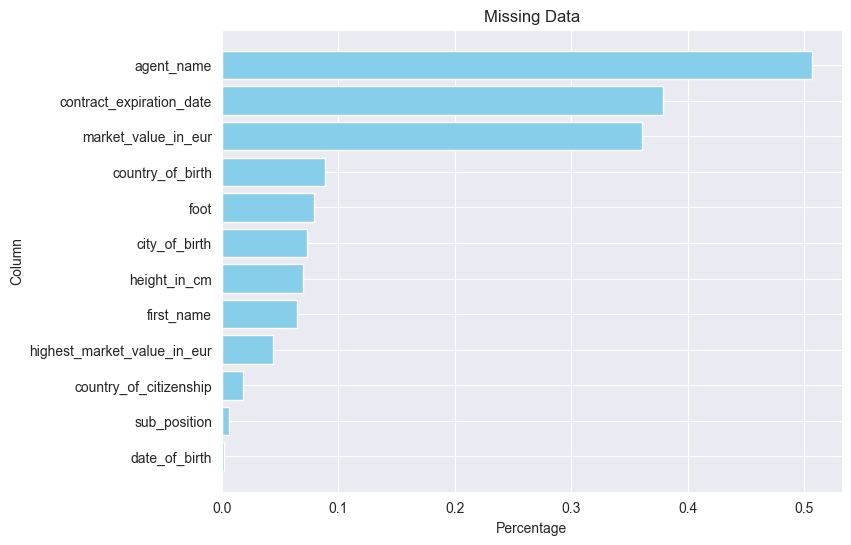

In [78]:
# calculate the percentage of missing values for each column
missing_data = df.isnull().mean()

# filter columns with missing values
missing_data = missing_data[missing_data > 0].sort_values(ascending=True)  

# plt.figure -> Create a new figure with dimensions 8x6
plt.figure(figsize=(8, 6))
plt.barh(missing_data.index, missing_data.values, color='skyblue')  # Use barh for horizontal bars
plt.title('Missing Data')
plt.xlabel('Percentage')
plt.ylabel('Column')
plt.xticks(rotation=0)
plt.show()


# Visualization of Missing Data in the Dataset

This section of the analysis focuses on identifying and visualizing the percentage of missing values for each column in the dataset.

 - The `isnull()` method returns a DataFrame of the same shape as `df` but with boolean values indicating whether each element is null (True) or not (False).
   - The `mean()` function is applied to calculate the average (percentage) of missing values per column.

 - We filtered the results to retain only those columns that have missing values. This is done by selecting only the indices with a mean greater than zero.

## Output:
The output of this code is a bar chart displaying the percentage of missing values for each column that contains null values. This visualization provides insights into the completeness of the dataset and helps identify areas that may require data imputation or further cleaning.


In [79]:
#df.loc -> Access a group of rows and columns by labels, so we can replace the missing values with 'unknown'
df.loc[df['agent_name'].isnull(), 'agent_name'] = 'unknown'
df.loc[df['contract_expiration_date'].isnull(), 'contract_expiration_date'] = 'unknown'
df.loc[df['country_of_birth'].isnull(), 'country_of_birth'] = 'unknown'
df.loc[df['foot'].isnull(), 'foot'] = 'unknown'
df.loc[df['city_of_birth'].isnull(), 'city_of_birth'] = 'unknown'

# Replace 'unknown' values with NaN, it's done in that way because the type of the column is float, so it will be easier to manage the missing values
df['market_value_in_eur'] = df['market_value_in_eur'].replace('unknown', pd.NA) 
df['height_in_cm'] = df['height_in_cm'].replace('unknown', pd.NA)
df['highest_market_value_in_eur'] = df['highest_market_value_in_eur'].replace('unknown', pd.NA) 
df

,player_id,first_name,last_name,name,last_season,current_club_id,player_code,country_of_birth,city_of_birth,country_of_citizenship,...,foot,height_in_cm,market_value_in_eur,highest_market_value_in_eur,contract_expiration_date,agent_name,image_url,url,current_club_domestic_competition_id,current_club_name
0,598,Timo,Hildebrand,Timo Hildebrand,2014,24,timo-hildebrand,Germany,Worms,Germany,...,unknown,NaN,NaN,10000000.0,unknown,unknown,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/timo-hildebran...,L1,Eintracht Frankfurt
1,670,Martin,Petrov,Martin Petrov,2012,714,martin-petrov,Bulgaria,Vratsa,Bulgaria,...,unknown,NaN,NaN,12000000.0,unknown,IFM,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/martin-petrov/...,ES1,RCD Espanyol Barcelona
2,1323,Martin,Amedick,Martin Amedick,2012,24,martin-amedick,Germany,Paderborn,Germany,...,unknown,NaN,NaN,2750000.0,unknown,unknown,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/martin-amedick...,L1,Eintracht Frankfurt
3,3195,Jermaine,Pennant,Jermaine Pennant,2013,512,jermaine-pennant,England,Nottingham,England,...,right,173.0,NaN,10500000.0,unknown,Andrew Sky,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/jermaine-penna...,GB1,Stoke City
4,3259,Damien,Duff,Damien Duff,2013,931,damien-duff,Ireland,Ballyboden,Ireland,...,left,177.0,NaN,17000000.0,unknown,unknown,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/damien-duff/pr...,GB1,Fulham FC
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30297,371851,Jaka,Bijol,Jaka Bijol,2023,410,jaka-bijol,Slovenia,Vuzenica,Slovenia,...,right,190.0,10000000.0,10000000.0,2027-06-30 00:00:00,MSC GROUP,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/jaka-bijol/pro...,IT1,Udinese Calcio
30298,537171,Semuel,Pizzignacco,Semuel Pizzignacco,2018,410,semuel-pizzignacco,Italy,Monfalcone,Italy,...,right,188.0,325000.0,350000.0,2025-06-30 00:00:00,unknown,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/semuel-pizzign...,IT1,Udinese Calcio
30299,586756,Festy,Ebosele,Festy Ebosele,2023,410,festy-ebosele,Ireland,"Enniscorthy, Wexford",Ireland,...,right,180.0,4500000.0,4500000.0,2027-06-30 00:00:00,The Kulture Group,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/festy-ebosele/...,IT1,Udinese Calcio
30300,704692,Nicolò,Cocetta,Nicolò Cocetta,2022,410,nicolo-cocetta,Italy,San Daniele del Friuli,Italy,...,unknown,NaN,75000.0,75000.0,2023-06-30 00:00:00,unknown,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/nicolo-cocetta...,IT1,Udinese Calcio


## Filling Missing Values in DataFrame

The following code addresses missing values in specific columns of the DataFrame `df`. Each column is checked for `null` values, and if any are found, they are replaced with the string `'unknown'`. This approach helps maintain data integrity and ensures that the DataFrame remains usable for further analysis.

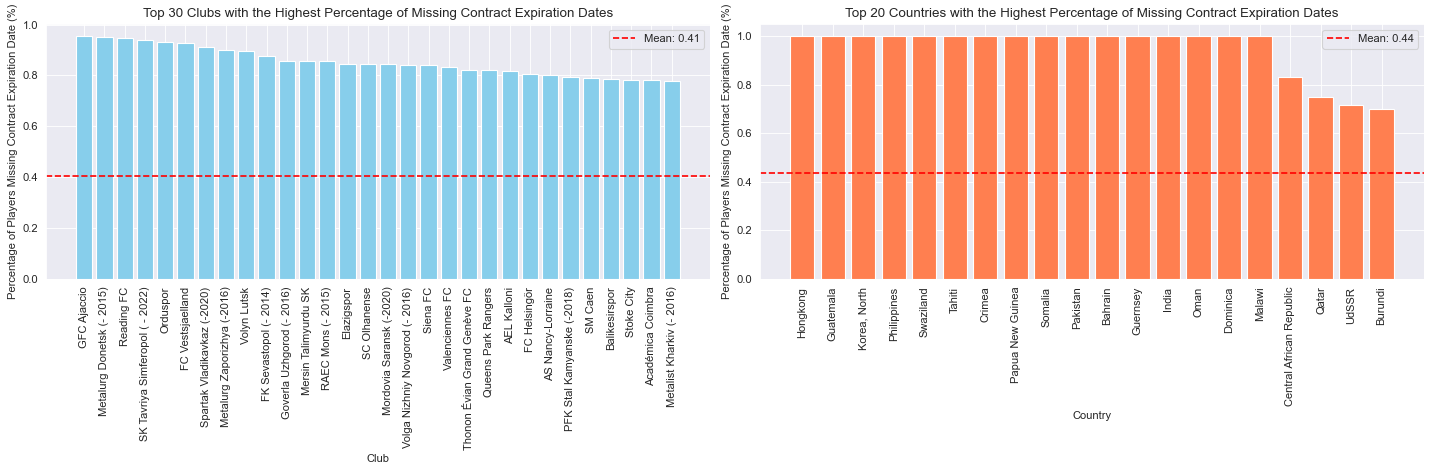

In [80]:
fig, axs = plt.subplots(1, 2, figsize=(18, 6), dpi=80)

#check for unknown values in the column contract_expiration_date for each club
missing_contract_club = df[df['contract_expiration_date'] == 'unknown'].groupby('current_club_name').size()

#counting the total number of players for each club
total_players_per_club = df.groupby('current_club_name').size()

#calculate the percentage of missing contract expiration dates for each club
percentage_missing = (missing_contract_club / total_players_per_club).sort_values(ascending=False)

#considering only clubs with missing values > 0%
percentage_missing = percentage_missing[percentage_missing > 0]
most_missing_clubs = percentage_missing.head(30)    #considering only the top 30 clubs

#Operations about the plot
axs[0].bar(most_missing_clubs.index, most_missing_clubs.values, color='skyblue')
axs[0].set_title('Top 30 Clubs with the Highest Percentage of Missing Contract Expiration Dates')
axs[0].set_xlabel('Club')
axs[0].set_ylabel('Percentage of Players Missing Contract Expiration Date (%)')
axs[0].set_xticks(range(len(most_missing_clubs.index)))
axs[0].set_xticklabels(most_missing_clubs.index, rotation=90)

mean_missing_contract = percentage_missing.mean()
axs[0].axhline(y=mean_missing_contract, color='r', linestyle='--', label=f'Mean: {mean_missing_contract:.2f}')

axs[0].legend()

#check for unknown values in the column contract_expiration_date for each country that exists in the dataset
missing_contract_country = df[df['contract_expiration_date'] == 'unknown'].groupby('country_of_birth').size()

#count the total number of players for each country
total_players_per_country = df.groupby('country_of_birth').size()

#calculate the percentage of missing contract expiration dates for each country
percentage_missing_country = (missing_contract_country / total_players_per_country).sort_values(ascending=False)

#create a subset of countries with missing values > 0%
percentage_missing_country = percentage_missing_country[percentage_missing_country > 0]
most_missing_countries = percentage_missing_country.head(20)    #considering only the top 20 countries

#Operations about the plot
axs[1].bar(most_missing_countries.index, most_missing_countries.values, color='coral')
axs[1].set_title('Top 20 Countries with the Highest Percentage of Missing Contract Expiration Dates')
axs[1].set_xlabel('Country')
axs[1].set_ylabel('Percentage of Players Missing Contract Expiration Date (%)')
axs[1].set_xticks(range(len(most_missing_countries.index)))
axs[1].set_xticklabels(most_missing_countries.index, rotation=90)

mean_missing_contract_country = percentage_missing_country.mean()
axs[1].axhline(y=mean_missing_contract_country, color='r', linestyle='--', label=f'Mean: {mean_missing_contract_country:.2f}')

axs[1].legend()

plt.tight_layout()
plt.show()


# Analysis of Missing Contract Expiration Dates

In this section, we analyze the missing values in the `contract_expiration_date` column of the dataset, both by clubs and by countries.

   - **Count Missing Contract Expiration Dates**:
     - We check for 'unknown' values in the `contract_expiration_date` column for each club and group the results using `groupby()`.
   - **Total Players per Club**:
     - We count the total number of players for each club using `groupby()`.
   - **Calculate Percentage of Missing Values**:
     - The percentage of missing contract expiration dates is calculated by dividing the number of missing values by the total number of players for each club, sorted in descending order.
   - **Filter for Non-zero Percentages**:
     - We filter the results to include only clubs with a percentage of missing values greater than 0%.
   - **Top 30 Clubs**:
     - We select the top 30 clubs with the highest percentage of missing contract expiration dates for plotting.

   - The same process is repeated for analyzing missing contract expiration dates by country.
   - We group the dataset by `country_of_birth` to find the number of missing values and the total players per country, followed by calculating the percentage of missing values.
   - Again, we filter for countries with a percentage greater than 0% and select the top 20 countries for plotting.

## Output:
The resulting visualizations display the percentage of players with missing contract expiration dates across both clubs and countries, facilitating insights into the data quality related to contract information.


# Data Cleaning

In [81]:
#check for missing values in the columns first_name and last_name
null_first_name = df['first_name'].isnull().sum()  
null_second_name = df['last_name'].isnull().sum()

#drop the columns first_name and last_name if there are missing values in at least one of them
if null_first_name != 0 or null_second_name != 0:
    df.drop(columns=['first_name', 'last_name'], inplace=True)

df

,player_id,name,last_season,current_club_id,player_code,country_of_birth,city_of_birth,country_of_citizenship,date_of_birth,sub_position,...,foot,height_in_cm,market_value_in_eur,highest_market_value_in_eur,contract_expiration_date,agent_name,image_url,url,current_club_domestic_competition_id,current_club_name
0,598,Timo Hildebrand,2014,24,timo-hildebrand,Germany,Worms,Germany,1979-04-05,Goalkeeper,...,unknown,NaN,NaN,10000000.0,unknown,unknown,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/timo-hildebran...,L1,Eintracht Frankfurt
1,670,Martin Petrov,2012,714,martin-petrov,Bulgaria,Vratsa,Bulgaria,1979-01-15,Left Winger,...,unknown,NaN,NaN,12000000.0,unknown,IFM,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/martin-petrov/...,ES1,RCD Espanyol Barcelona
2,1323,Martin Amedick,2012,24,martin-amedick,Germany,Paderborn,Germany,1982-09-06,Centre-Back,...,unknown,NaN,NaN,2750000.0,unknown,unknown,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/martin-amedick...,L1,Eintracht Frankfurt
3,3195,Jermaine Pennant,2013,512,jermaine-pennant,England,Nottingham,England,1983-01-15,Right Winger,...,right,173.0,NaN,10500000.0,unknown,Andrew Sky,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/jermaine-penna...,GB1,Stoke City
4,3259,Damien Duff,2013,931,damien-duff,Ireland,Ballyboden,Ireland,1979-03-02,Right Midfield,...,left,177.0,NaN,17000000.0,unknown,unknown,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/damien-duff/pr...,GB1,Fulham FC
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30297,371851,Jaka Bijol,2023,410,jaka-bijol,Slovenia,Vuzenica,Slovenia,1999-02-05,Centre-Back,...,right,190.0,10000000.0,10000000.0,2027-06-30 00:00:00,MSC GROUP,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/jaka-bijol/pro...,IT1,Udinese Calcio
30298,537171,Semuel Pizzignacco,2018,410,semuel-pizzignacco,Italy,Monfalcone,Italy,2001-09-01,Goalkeeper,...,right,188.0,325000.0,350000.0,2025-06-30 00:00:00,unknown,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/semuel-pizzign...,IT1,Udinese Calcio
30299,586756,Festy Ebosele,2023,410,festy-ebosele,Ireland,"Enniscorthy, Wexford",Ireland,2002-08-02,Right Midfield,...,right,180.0,4500000.0,4500000.0,2027-06-30 00:00:00,The Kulture Group,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/festy-ebosele/...,IT1,Udinese Calcio
30300,704692,Nicolò Cocetta,2022,410,nicolo-cocetta,Italy,San Daniele del Friuli,Italy,2003-12-19,Centre-Back,...,unknown,NaN,75000.0,75000.0,2023-06-30 00:00:00,unknown,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/nicolo-cocetta...,IT1,Udinese Calcio


# Handling Missing Values in Player Names

In this section, we check for missing values in the `first_name` and `last_name` columns of the dataset. If any missing values are found, the entire columns for `first_name` and `last_name` are dropped from the DataFrame.

## Code Explanation:

1. **Count Missing Values**:
   - We counts the number of missing (null) values in the `first_name` and `last_name` columns using the `isnull()` method combined with `sum()`.

2. **Print Null Counts**:
   - The counts of missing values for both columns are printed to provide an overview of the data quality.

3. **Drop Columns if Missing Values Exist**:
   - If either column has missing values both the `first_name` and `last_name` columns are dropped from the DataFrame 

## Output:
The final DataFrame is displayed after these operations, which will no longer include the `first_name` and `last_name` columns if they contained any missing values.

This process ensures that our dataset remains clean and does not contain any columns with missing values that could affect further analyses.

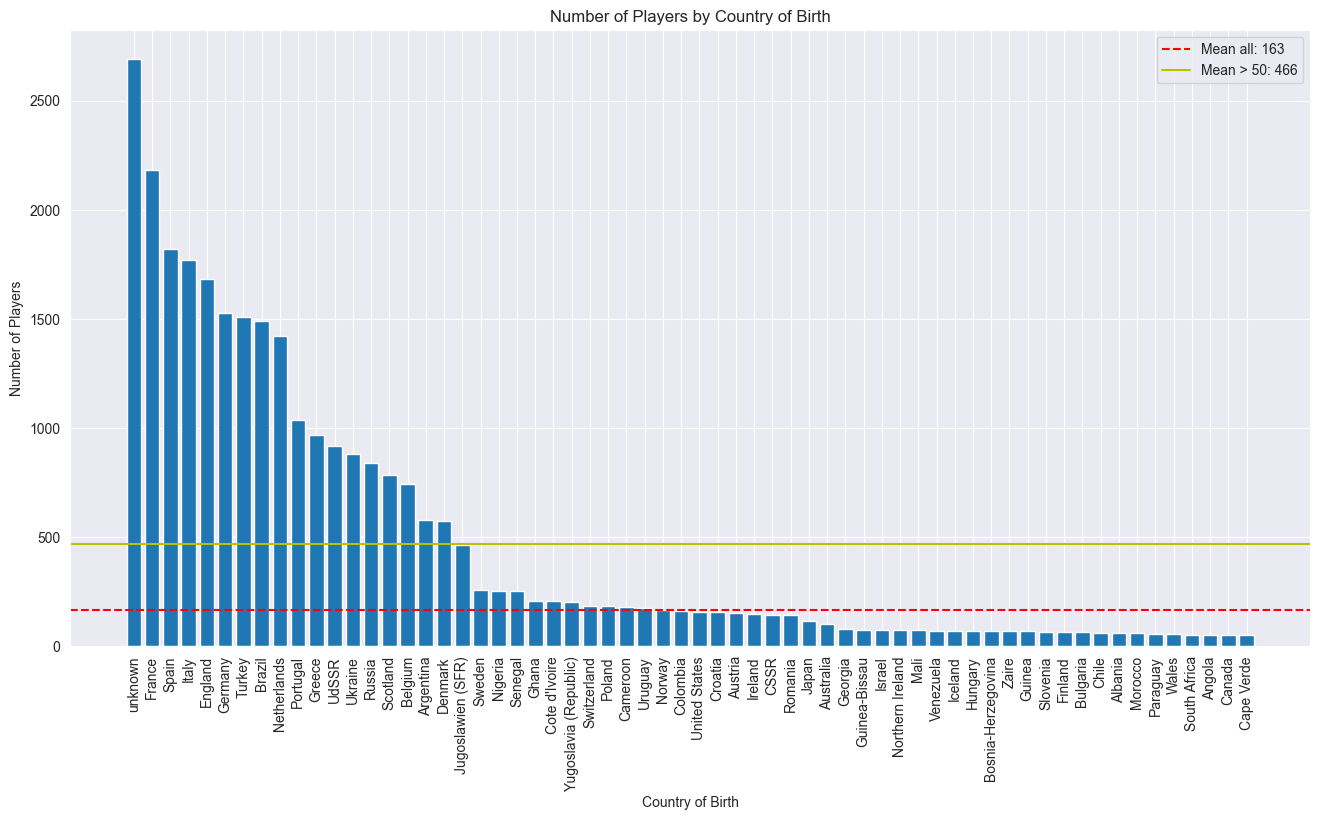

In [82]:
# group by country of birth and count the number of players for each country
grouped_df = df.groupby('country_of_birth')['player_id'].count().reset_index(name = 'count')
grouped_df.sort_values(by='count', ascending=False, inplace=True)
grouped_df_fifty = grouped_df[grouped_df['count'] >= 50]

# plot operations
plt.figure(figsize=(16, 8))
plt.bar(grouped_df_fifty['country_of_birth'], grouped_df_fifty['count'])
plt.title('Number of Players by Country of Birth')
plt.xlabel('Country of Birth')
plt.ylabel('Number of Players')

# mean of players from all countries
total_mean = int(grouped_df['count'].mean())
legend = "Mean all: " + str(total_mean)
plt.axhline(y=grouped_df['count'].mean(), color='r', linestyle='--', label=legend)

# mean of players from countries with at least 50 players
legend_fifty = "Mean > 50: " + str(int(grouped_df_fifty['count'].mean()))
plt.axhline(y=grouped_df_fifty['count'].mean(), color='y', linestyle='-', label=legend_fifty)

plt.legend()
plt.xticks(rotation=90)
plt.show() 

# Number of Players by Country of Birth

This bar chart visualizes the distribution of football players based on their `country_of_birth`. The data has been grouped by country, counting the number of players from each country, and it only includes countries with at least 50 players in the dataset.

##  Observations:

- **Countries Represented**: The chart shows countries with significant representation in the dataset, allowing for comparisons among them.
    The unknown one unify all the players with unknown `country_of_birth`.
- **Mean Values**:
  - The red dashed line indicates the average number of players across all countries in the dataset, which provides a benchmark for understanding overall representation.
  - The yellow solid line represents the average number of players from countries with at least 50 players. This line helps highlight which countries are above or below this average.
  
## Conclusion:
This visualization allows for a quick assessment of player distribution by country, providing insights into which countries contribute more players to the dataset. It can be useful for understanding trends in player nationality and potential biases in player representation within the dataset.


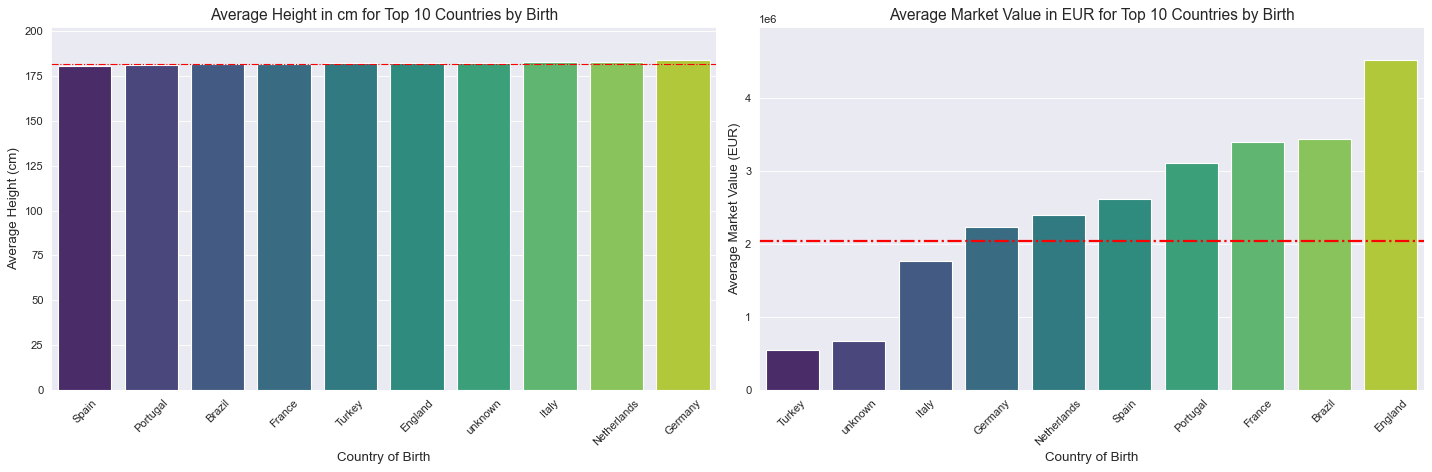

In [83]:
#the columns are converted to numeric type, non-numeric values are converted to NaN
df['height_in_cm'] = pd.to_numeric(df['height_in_cm'], errors='coerce')
df['market_value_in_eur'] = pd.to_numeric(df['market_value_in_eur'], errors='coerce')

N = 10  # Number of top countries to consider
# Group by country of birth and count the number of players for each country
grouped_df_fifty = df.groupby('country_of_birth')['player_id'].count().reset_index(name='count')
grouped_df_fifty.sort_values(by='count', ascending=False, inplace=True)

# Select the top N countries with the most players
top_10_countries = grouped_df_fifty.head(N)['country_of_birth']
df_top_10 = df[df['country_of_birth'].isin(top_10_countries)]

fig, axs = plt.subplots(1, 2, figsize=(18, 6), dpi=80)

# Calculate mean height per country for top 10 countries
mean_height_per_country = df_top_10.groupby('country_of_birth')['height_in_cm'].mean().sort_values(ascending=True)
mean_height_per_country_total = df.groupby('country_of_birth')['height_in_cm'].mean().sort_values(ascending=True)

# Plotting average height
sns.barplot(x=mean_height_per_country.index, y=mean_height_per_country.values, hue=mean_height_per_country.index, palette='viridis', ax=axs[0], legend=False)
axs[0].set_title(f'Average Height in cm for Top {N} Countries by Birth', fontsize=14)
axs[0].set_xlabel('Country of Birth', fontsize=12)
axs[0].set_ylabel('Average Height (cm)', fontsize=12)
axs[0].tick_params(axis='x', rotation=45)
max_height = mean_height_per_country.values.max()
axs[0].axhline(y=mean_height_per_country_total.mean(), color='r', linestyle='-.', label='Mean Height of All Countries', linewidth=1)
axs[0].set_ylim(0, max_height * 1.1)  # Extend y-axis by 10%

# Calculate mean market value per country for top 10 countries
mean_market_value_per_country = df_top_10.groupby('country_of_birth')['market_value_in_eur'].mean().sort_values(ascending=True)
mean_market_value_per_country_total = df.groupby('country_of_birth')['market_value_in_eur'].mean().sort_values(ascending=True)

# Plotting average market value
sns.barplot(x=mean_market_value_per_country.index, y=mean_market_value_per_country.values, hue=mean_market_value_per_country.index, palette='viridis', ax=axs[1], legend=False)
axs[1].set_title(f'Average Market Value in EUR for Top {N} Countries by Birth', fontsize=14)
axs[1].set_xlabel('Country of Birth', fontsize=12)
axs[1].set_ylabel('Average Market Value (EUR)', fontsize=12)
axs[1].tick_params(axis='x', rotation=45)
max_value = mean_market_value_per_country.values.max()
axs[1].axhline(y=mean_market_value_per_country_total.mean(), color='r', linestyle='-.', label='Mean Market Value of All Countries', linewidth=2)
axs[1].set_ylim(0, max_value * 1.1)  # Extend y-axis by 10%

# Adjust layout and display plot
plt.tight_layout()
plt.show()

# Average Height and Market Value by Country of Birth

This dual bar chart visualizes the average `height_in_cm` and average `market_value_in_eur` of football players based on their `country_of_birth`. The analysis focuses on the top 10 countries with the highest number of players, as identified in the dataset.

## Observations:

- **Top Countries**: The charts highlight the top 10 countries contributing players, facilitating comparisons in both average `height_in_cm` and `market_value_in_eur` among these nations. The unknown one unify all the players with unknown `country_of_birth`.
  
- **Mean Values**:
  - In the **average height** chart, the red dashed line indicates the mean height of players across all countries, serving as a benchmark for evaluating the height of players from the top 10 countries.
  - In the **average market value** chart, the red dashed line represents the mean market value across all countries, helping to identify which countries exceed or fall below this average.
  
- **Height Distribution**: The first chart provides insights into the physical stature of players, allowing stakeholders to see which countries produce taller athletes on average.
  
- **Market Value Insights**: The second chart offers a perspective on the financial valuation of players from these countries, which can reflect both the quality and popularity of football in these nations.

## Conclusion:
This visualization provides a comprehensive overview of the average `height_in_cm` and `market_value_in_eur` of football players by country. It helps in understanding not only the physical characteristics of players from different countries, but also their market valuation, which can be indicative of the countries' football development and success. Such insights can be useful for clubs, scouts, and analysts in making informed decisions regarding player acquisitions and scouting strategies.


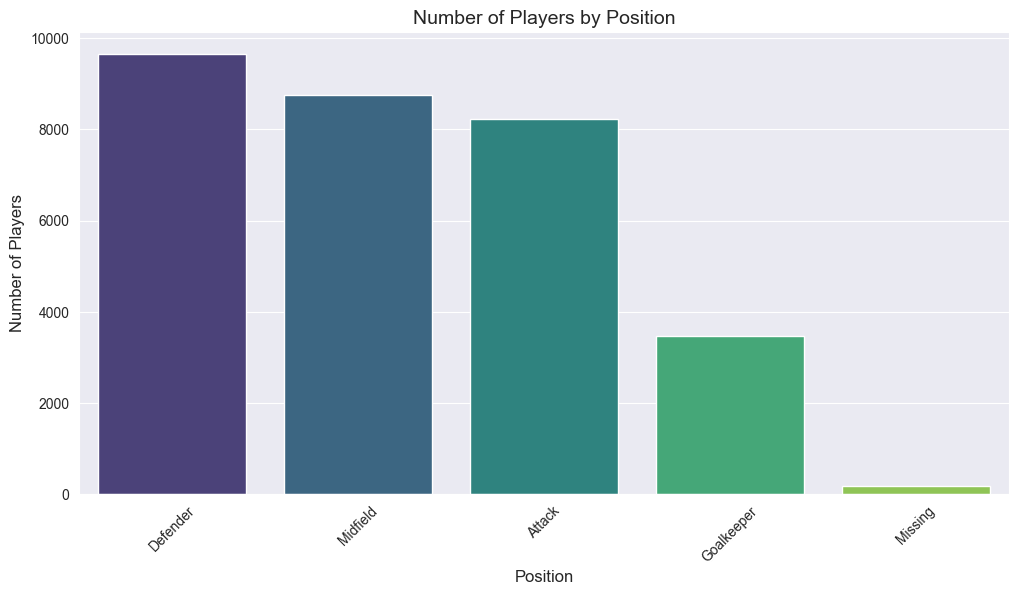

In [84]:
position_counts = df['position'].value_counts()
plt.figure(figsize=(12, 6))
sns.barplot(x=position_counts.index, y=position_counts.values, hue=position_counts.index ,palette='viridis')
plt.title('Number of Players by Position', fontsize=14)
plt.xlabel('Position', fontsize=12)
plt.ylabel('Number of Players', fontsize=12)
plt.xticks(rotation=45)
plt.show()


# Number of Players by Position

This bar chart visualizes the distribution of football players based on their playing positions. The data has been grouped by `position`, counting the number of players for each position.

## Observations:

- **Most Common Positions**: The most frequent `positions` is defender. This could be due to formation tactics or a larger pool of players in those positions.

- **Least Common Positions**: Positions with fewer players is goalkeeper, it's normal because we can assume that in a team there are maximum three goalkeeper.

## Conclusion:
This visualization allows for a quick assessment of the distribution of football players by position.

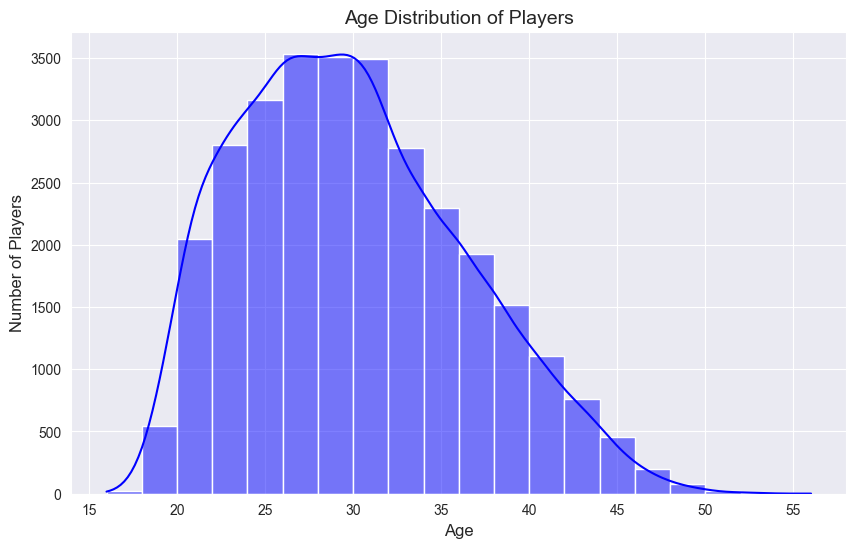

In [85]:
# Age Distribution
df['date_of_birth'] = pd.to_datetime(df['date_of_birth'], errors='coerce')
# Calculate age of players using the current date
df['age'] = (pd.Timestamp.now() - df['date_of_birth']).dt.days // 365
plt.figure(figsize=(10, 6))
sns.histplot(df['age'], bins=20, kde=True, color='blue')
plt.title('Age Distribution of Players', fontsize=14)
plt.xlabel('Age', fontsize=12)
plt.ylabel('Number of Players', fontsize=12)
plt.show()

# Age Distribution of Players

This histogram visualizes the age distribution of football players in the dataset. The age of each player was calculated from their `date_of_birth`, and the distribution is shown along with a kernel density estimate to highlight the underlying trends in the data.

## Observations:

- **Age Range**: The plot shows the full range of ages for players, providing insights into the spread of younger vs. older players.
  
- **Most Common Ages**: The highest bars in the histogram represent the ages where the most players are concentrated, indicating a peak in the age distribution of footballers in this dataset.
  
- **KDE Line**: The smooth KDE line overlays the histogram, offering a clearer view of the general age trend, highlighting where the most players are likely to fall age-wise.

## Conclusion:
This visualization helps identify the age distribution of players, allowing for the analysis of player age trends.

# Correlation between height and market value

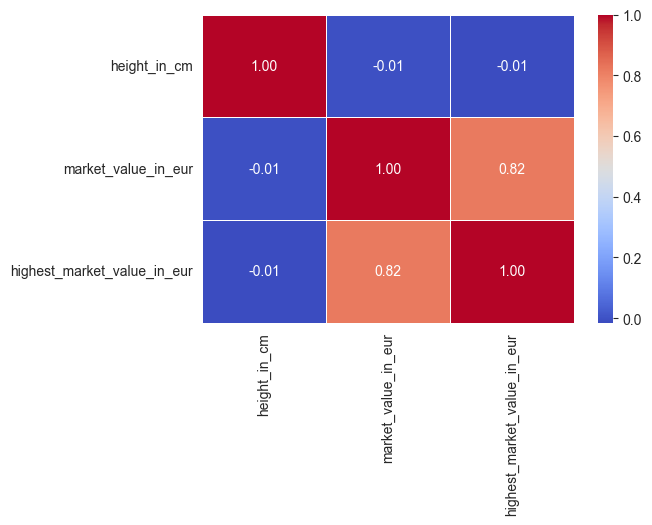

In [86]:
# Select numerical columns for correlation analysis
numerical_cols = ['height_in_cm', 'market_value_in_eur', 'highest_market_value_in_eur']

# Calculate the correlation matrix
correlation_matrix = df[numerical_cols].corr()

# Heatmap della correlazione
plt.figure(figsize=(6, 4), dpi=100)
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', linewidths=.5)
plt.xticks(rotation=90)
plt.show()

This heatmap visualizes the correlation between the numerical columns in the dataset. The numerical columns analyzed are:
- **`Height_in_cm`**: Represents the height of the players in centimeters.
- **`Market_Value_in_EUR`**: Represents the market value of the players in euros.
- **`Highest_Market_Value_in_EUR`**: Represents the highest recorded market value of the players in euros.
## Interpretation of Correlation Coefficients:

- **Height in cm**:
  - Has a negative correlation with both **`market_value_in_eur`** (-0.01) and **`highest_market_value_in_eur`** (-0.01), suggesting that height does not have a strong relationship with market values.

- **Market Value in EUR**:
  - Displays a strong positive correlation with **`highest_market_value_in_eur`** (0.82), indicating that players with higher current market values tend to have higher recorded market values.

- **Highest Market Value in EUR**:
  - Shows a strong positive correlation with **`market_value_in_eur`** (0.82) and a negligible negative correlation with **`height_in_cm`** (-0.01).

## Conclusion:
This correlation matrix reveals important relationships within the data, particularly the strong positive correlation between **`market_value_in_eur`** and **`highest_market_value_in_eur`**. However, `height_in_cm` appears to have little correlation with market values, indicating that other factors may influence a player's market value more significantly.

In [87]:
# Save the cleaned dataset to a new CSV file
df.to_csv('../cleaned_csv/players_cleaned.csv', index=False)